In [12]:
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from Losses import PricingLoss

In [13]:
import numpy as np
import mbtr.utils as ut
from scipy.linalg import hankel
from scipy.stats import expon
import matplotlib.pyplot as plt
from mbtr.mbtr import MBT
from mbtr.utils import set_figure
from mbtr import LOSS_MAP
from Losses.PricingLoss import PricingLikelihood

LOSS_MAP['pricing'] = PricingLikelihood # this line has to be added for the MBT class to recognize the PricingLikelihood subclass as a type of loss

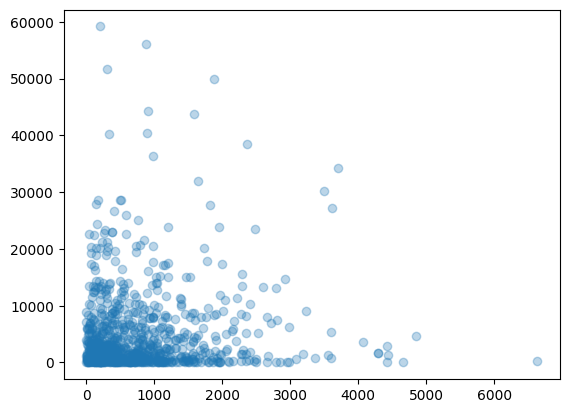

In [14]:
from Data.pg15_cleaning import pg15_training

joint_severity = pg15_training[(pg15_training['AvIndtppd'] != 0) & (pg15_training['AvIndtpbi'] != 0)]
material_damage = joint_severity['AvIndtppd']
bodily_injury = joint_severity['AvIndtpbi']

plt.scatter(material_damage, bodily_injury, alpha = 0.3)
plt.show()

KendalltauResult(correlation=0.00703175958382165, pvalue=0.7563276414453457)


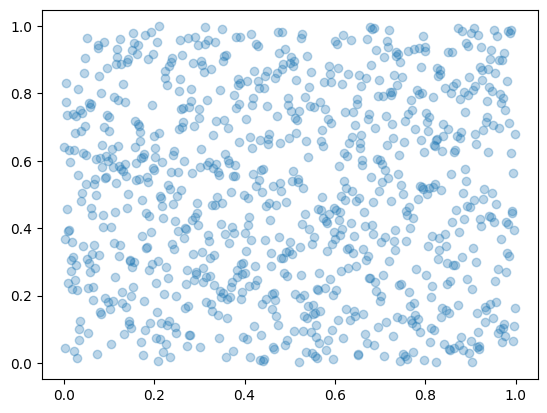

In [15]:
import scipy.stats as stats

def rank_pseudo_obs(y):
        """
        Return rank-based pseudo-observations from initial target matrix

        :param y: observation matrix (n_obs, 2)

        :return: rank-based pseudo-observations matrix (n_obs, 2)
        """
        n_obs = y.shape[0]
        u1 = stats.rankdata(y[:, 0])/(n_obs + 1)
        u2 = stats.rankdata(y[:, 1])/(n_obs + 1)
        return np.hstack((u1.reshape(-1,1), u2.reshape(-1,1)))

sev_array = joint_severity[['AvIndtppd', 'AvIndtpbi']].to_numpy()
residuals = rank_pseudo_obs(sev_array)

print(stats.kendalltau(residuals[:, 0], residuals[:, 1]))
plt.scatter(residuals[:, 0], residuals[:, 1], alpha = 0.3)
plt.show()

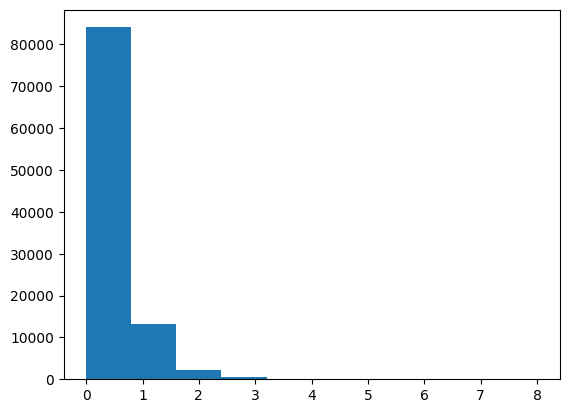

In [16]:
plt.hist(pg15_training['TotalNum'])
plt.show()

In [17]:
covariates = pg15_training.loc[ : , ~pg15_training.columns.isin(['PolNum', 'CalYear', 'SubGroup2', 'Exppdays', 'Numtppd', 'Numtpbi', 'Indtppd', 'Indtpbi', 'TotalNum', 'Exposure', 'AvIndtppd', 'AvIndtpbi'])]
output = pg15_training[['TotalNum', 'Numtppd', 'AvIndtppd', 'AvIndtpbi', 'Exposure']]

x = covariates.to_numpy()
y = output.to_numpy()

In [18]:
import scipy.special as special

def gamma_lpdf_grad_eta1(y, eta1, eta2):
        return np.where(y != 0, np.log(y) - special.psi(eta1+1) + np.log(eta2), 0)

def get_initial_guess(y):
        """
        Return an initial guess for the prediction. This is loss-specific. We set the marginal parameters to global MLE estimates and assume independence i.e. copula parameter = 0.

        :param y: target matrix of the training set

        :return: np.ndarray with (transformed) parameter initial guess i.e. (r, logodds, natshape1, natrate1, natshape2, natrate2, rho)
        """
        expo = y[:, -1].reshape(-1,1)
        n = y[:, 0].reshape(-1,1)
        t = y[:, 1].reshape(-1,1)
        y1 = y[:, 2].reshape(-1,1)
        y2 = y[:, 3].reshape(-1,1)
        r_hat0 = np.log(np.sum(n, axis = 0)/np.sum(expo, axis = 0))
        p0 = np.sum(t)/np.sum(n)
        logodds_hat0 = special.logit(p0)
        shape_fit1, _, scale_fit1 = stats.gamma.fit(y1[np.nonzero(y1)], floc=0)
        shape_fit2, _, scale_fit2 = stats.gamma.fit(y2[np.nonzero(y2)], floc=0)
        nat_shape1_hat0 = np.log(shape_fit1 + 1)
        nat_rate1_hat0 = np.log(1/scale_fit1)
        nat_shape2_hat0 = np.log(shape_fit2 + 1)
        nat_rate2_hat0 = np.log(1/scale_fit2)
        return np.hstack((r_hat0*np.ones((y.shape[0], 1)), logodds_hat0*np.ones((y.shape[0], 1)), nat_shape1_hat0*np.ones((y.shape[0], 1)), nat_rate1_hat0*np.ones((y.shape[0], 1)), nat_shape2_hat0*np.ones((y.shape[0], 1)) , nat_rate2_hat0*np.ones((y.shape[0], 1)), np.zeros((y.shape[0], 1))))

y_hat = get_initial_guess(y)
eta1 = (np.exp(y_hat[:, 4])-1).reshape(-1,1)
eta2 = np.exp(y_hat[:, 5]).reshape(-1,1)
y1 = y[:, 2].reshape(-1, 1)
y2 = y[:, 3].reshape(-1, 1)
gamma_lpdf_grad_eta1(y1, eta1, eta2)

def rank_pseudo_obs(y):
        """
        Return rank-based pseudo-observations from initial target matrix

        :param y: observation matrix (n_obs, 2)

        :return: rank-based pseudo-observations matrix (n_obs, 2)
        """
        n_obs = y.shape[0]
        u1 = stats.rankdata(y[:, 0])/(n_obs + 1)
        u2 = stats.rankdata(y[:, 1])/(n_obs + 1)
        return np.hstack((u1.reshape(-1,1), u2.reshape(-1,1)))

#u = np.where(y1 != 0 and y2 != 0, rank_pseudo_obs(np.hstack((y1, y2))), np.zeros((0,0)))

C:\Users\antho\AppData\Local\Temp\ipykernel_28600\104622280.py:4: RuntimeWarning: divide by zero encountered in log
  return np.where(y != 0, np.log(y) - special.psi(eta1+1) + np.log(eta2), 0)


In [19]:
m = MBT(n_boosts = 10, learning_rate = 0.3, loss_type = "pricing", refit = False, warmup = 5).fit(x, y, do_plot = False)

  0%|          | 0/10 [00:00<?, ?it/s]c:\Users\antho\master-thesis-project\Losses\PricingLoss.py:77: RuntimeWarning: divide by zero encountered in log
  return np.where(y != 0, np.log(y) - special.psi(eta1+1) + np.log(eta2), 0)
100%|██████████| 10/10 [10:56<00:00, 65.64s/it]

#---------------- Model fitted in 1.09e+01 min ----------------


In [24]:
loss = PricingLikelihood(warmup = 1)
tpar = m.predict(x)
par = np.hstack((np.exp(tpar[:, 0]).reshape(-1,1), special.expit(tpar[:,1]).reshape(-1,1), np.exp(tpar[:, 2]).reshape(-1,1), np.exp(tpar[:, 3]).reshape(-1,1), np.exp(tpar[:, 4]).reshape(-1,1), np.exp(tpar[:, 5].reshape(-1,1)), loss.cop_par_inv_link(tpar[:, -1].reshape(-1,1))))

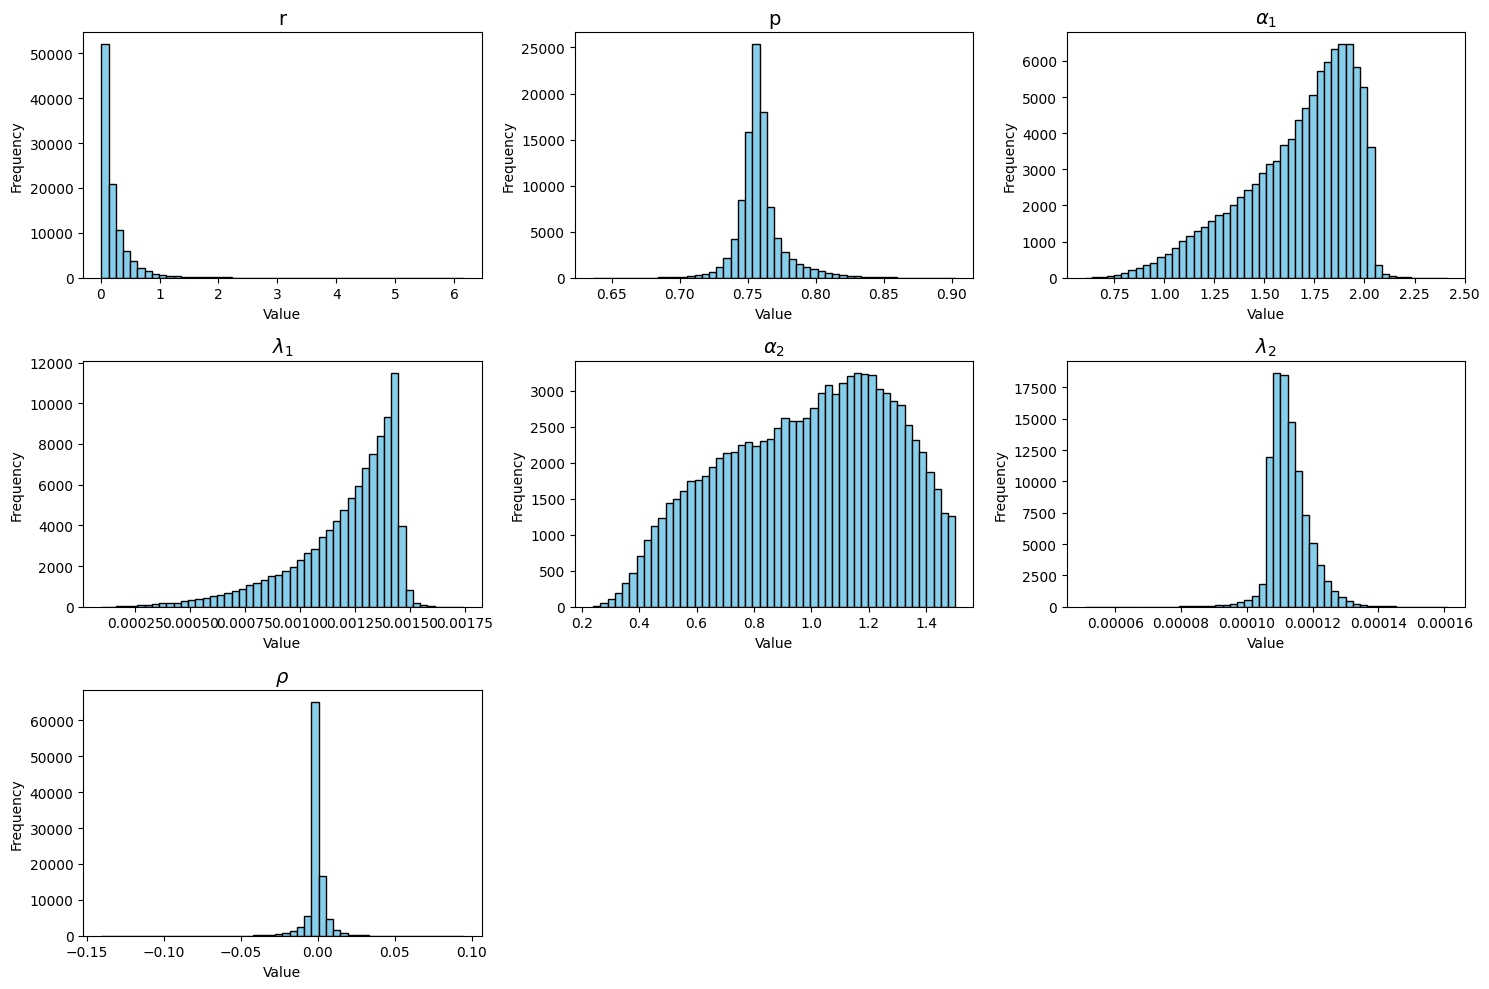

In [25]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()  # Flatten to easily iterate

param_names = ["r", "p", r"$\alpha_1$", r"$\lambda_1$", r"$\alpha_2$", r"$\lambda_2$", r"$\rho$"]
# Plot histogram for each parameter
for i in range(7):
    axes[i].hist(par[:, i], bins=50, color='skyblue', edgecolor='black')
    axes[i].set_title(param_names[i], fontsize=14)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Hide unused subplots (in case of 9 total)
for j in range(7, 9):
    axes[j].axis('off')

plt.tight_layout()
plt.show()